# Clasificación landuse con CNN

Se entrenan dos variantes sobre las tres clases locales (`denseresidential`,
`harbor`, `river`) y cada una guarda sus resultados en una carpeta independiente:

| Variante | Carpeta | Descripción |
|---|---|---|
| CNN base | `resultados/cnn/base/` | Arquitectura del ejemplo: 8 → 16 → 32 filtros, `Flatten` + `Dense(3)`. |
| CNN mejorada | `resultados/cnn/mejorada/` | Más filtros, `BatchNormalization`, `Dropout`, `GlobalAveragePooling` y augmentación. |

Las imágenes se redimensionan a 128×128 y se normalizan a `[0, 1]`. El split es
el común del reto: 75 % train, 15 % validación y 25 % test. El test **no** se usa
para early stopping.

Los modelos ya entrenados se cargan por defecto. Para volver a entrenarlos,
cambia `FORCE_RETRAIN = True` en la celda de configuración.

## Configuración

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import (
    Activation,
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    Input,
    MaxPooling2D,
)
from keras.models import Sequential
from keras.optimizers import Adam

import common_landuse as cl

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cl.SEED)
np.random.seed(cl.SEED)

I0000 00:00:1794800553.569465   91877 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794800553.653347   91877 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794800556.185876   91877 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Carga del dataset y split común

In [2]:
data = cl.load_split_data()
X_train = data["X_train"].astype("float32") / 255.0
X_val = data["X_val"].astype("float32") / 255.0
X_test = data["X_test"].astype("float32") / 255.0
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cl.one_hot(y_train_labels)
y_val = cl.one_hot(y_val_labels)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Test distribution:", {name: int(np.sum(y_test_labels == name)) for name in cl.CLASSES})

Train: (956, 128, 128, 3) | Validation: (169, 128, 128, 3) | Test: (375, 128, 128, 3)
Test distribution: {'denseresidential': 125, 'harbor': 125, 'river': 125}


## Arquitecturas

In [3]:
def build_base_cnn():
    model = Sequential(
        [
            Input(shape=(128, 128, 3)),
            Conv2D(8, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Conv2D(16, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Conv2D(32, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Flatten(),
            Dense(len(cl.CLASSES)),
            Activation("softmax"),
        ],
        name="cnn_base",
    )
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model


def conv_block(x, filters):
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return MaxPooling2D((2, 2))(x)


def build_improved_cnn():
    inputs = Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(len(cl.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_improved")
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model

## Entrenamiento o carga desde caché

In [4]:
def fit_base(model):
    history, seconds = cl.train_keras_model(
        model, X_train, y_train, X_val, y_val, epochs=15, batch_size=32
    )
    return model, history, seconds


def evaluate_base(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cl.predict_keras(model, X_test)
    predicted = np.array(cl.CLASSES)[predicted_idx]
    metrics = cl.compute_metrics(
        name="CNN base",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [8, 16, 32],
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch_size": 32,
            "epochs": 15,
            "augmentation": False,
        },
        notes="Sequential architecture from the professor's base notebook.",
    )
    cl.save_results(
        "cnn/base",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics


def fit_improved(model):
    callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    ]
    history, seconds = cl.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=40,
        batch_size=32,
        callbacks=callbacks,
    )
    return model, history, seconds


def evaluate_improved(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cl.predict_keras(model, X_test)
    predicted = np.array(cl.CLASSES)[predicted_idx]
    metrics = cl.compute_metrics(
        name="CNN mejorada",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [32, 64, 128],
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch_size": 32,
            "epochs_max": 40,
            "augmentation": True,
            "dropout": 0.4,
            "early_stopping": 8,
        },
        notes="CNN with BatchNorm, Dropout, GAP, augmentation and callbacks.",
    )
    cl.save_results(
        "cnn/mejorada",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics

In [5]:
model_base, history_base, metrics_base, retrained_base = cl.load_or_train(
    "cnn/base",
    build_model=build_base_cnn,
    fit_model=fit_base,
    evaluate_model=evaluate_base,
    force=FORCE_RETRAIN,
)
print("Test accuracy:", round(metrics_base["accuracy"], 4))

E0000 00:00:1794800566.131768   91877 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1794800566.132230   91947 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1794800566.148036   91877 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/andres/Des

[cache] Using trained model from /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/base
Test accuracy: 0.8773


In [6]:
model_improved, history_improved, metrics_improved, retrained_improved = cl.load_or_train(
    "cnn/mejorada",
    build_model=build_improved_cnn,
    fit_model=fit_improved,
    evaluate_model=evaluate_improved,
    force=FORCE_RETRAIN,
)
print("Test accuracy:", round(metrics_improved["accuracy"], 4))

[cache] Using trained model from /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/mejorada
Test accuracy: 0.976


## Comparación de las dos variantes

In [7]:
comparison = pd.DataFrame(
    [
        {
            "model": metrics_base["name"],
            "accuracy": metrics_base["accuracy"],
            "f1_macro": metrics_base["f1_macro"],
            "parameters": metrics_base["parameters"],
            "training_seconds": metrics_base["training_seconds"],
        },
        {
            "model": metrics_improved["name"],
            "accuracy": metrics_improved["accuracy"],
            "f1_macro": metrics_improved["f1_macro"],
            "parameters": metrics_improved["parameters"],
            "training_seconds": metrics_improved["training_seconds"],
        },
    ]
)
display = comparison.rename(
    columns={
        "model": "Modelo",
        "accuracy": "Accuracy",
        "f1_macro": "F1 macro",
        "parameters": "Parámetros",
        "training_seconds": "Entrenamiento (s)",
    }
)
display.round(4)

,Modelo,Accuracy,F1 macro,Parámetros,Entrenamiento (s)
0,CNN base,0.8773,0.8755,30611,76.03
1,CNN mejorada,0.9760,0.9760,305251,2062.72


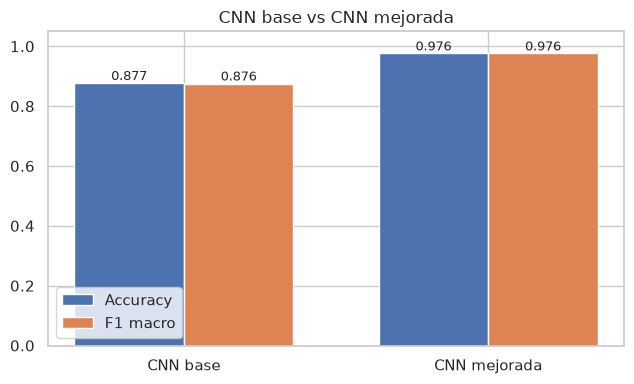

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
positions = np.arange(len(comparison))
width = 0.36
ax.bar(positions - width / 2, comparison["accuracy"], width, label="Accuracy")
ax.bar(positions + width / 2, comparison["f1_macro"], width, label="F1 macro")
ax.set_xticks(positions, comparison["model"])
ax.set_ylim(0, 1.05)
ax.set_title("CNN base vs CNN mejorada")
ax.legend()
for index, (accuracy, f1_value) in enumerate(
    zip(comparison["accuracy"], comparison["f1_macro"])
):
    ax.text(index - width / 2, accuracy + 0.01, f"{accuracy:.3f}", ha="center", fontsize=9)
    ax.text(index + width / 2, f1_value + 0.01, f"{f1_value:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## Observaciones

* La CNN base aprende rápido, pero sobreajusta: la accuracy de entrenamiento sube
  mucho más que la de validación. Aun así, supera el 87 % en test.
* La CNN mejorada controla ese sobreajuste con `BatchNormalization`, `Dropout`,
  `GlobalAveragePooling` y augmentación, y gana casi 10 puntos porcentuales.
* El coste es un entrenamiento mucho más largo en CPU. El flag
  `FORCE_RETRAIN = False` permite reutilizar los modelos ya guardados y evitar
  ese coste al revisar el cuaderno.